In [124]:
#Imports
import os
import mne
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, ShuffleSplit

from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

mne.set_log_level("WARNING")


### Constants and model setup

Signals are sampled at $f_s = 250\,\text{Hz}$ from 8 channels (C4, C3, Cz, Fz, PO7, Pz, PO8, Oz). `bandpass` defines 29 one-hertz bands, $f \in (i, i+1)\,\text{Hz}$ for $i = 1, \dots, 29$, so each band can be scored separately.

The classifier is CSP followed by LDA:
- **CSP** keeps 4 spatial filters $w_i$, with Ledoit-Wolf regularised covariances. Each epoch becomes 4 features $\log\,\text{var}(w_i^\top X)$.
- **LDA** fits a linear decision boundary on those 4 features.

Accuracy is estimated with `ShuffleSplit` (80% train, 20% test, fixed seed).

In [125]:
#Variable & Constant
result = []
SFREQ = 250 #Frequency of the eeg
ch_names = ['C4', 'C3', 'Cz','Fz','PO7','Pz','PO8','Oz'] #Channels used in the eeg
bandpass = [(i,i+1) for i in range(1,30)]
#bandpass = [(7,12),(18,24)]
cv = ShuffleSplit(test_size=0.2,random_state=67)
lda = LDA()
csp = CSP(n_components=4, reg="ledoit_wolf", log=True, norm_trace=False)
clf = Pipeline([("CSP",csp),("LDA",lda)])
mark = [["move","rest"],["cue_start"]]

### Load, filter, and separate into epochs

`convertRaw` turns CSV files into epochs. For training, the three runs are concatenated into an EEG array $X \in \mathbb{R}^{8 \times T}$, where $T$ is the total number of samples. For testing, a single file is loaded.

Markers are converted to annotations at each cue onset: `move` and `rest` for training, `cue_start` for testing. For each band, a filtered copy of the raw data is made and cut into epochs with $t \in (0.5, 4.5)\,\text{s}$ after the cue, skipping the first 0.5 s to account for reaction delay. Training labels come from the event codes.

In [126]:
def convertRaw(PATH,target):
    #0-> train 1->test
    if target == 0:
        df = pd.concat([pd.read_csv(path) for path in PATH],ignore_index=True)
    else:
        df = pd.read_csv(PATH)
    data = df[ch_names].to_numpy().T
    info = mne.create_info(ch_names=ch_names,sfreq=SFREQ,ch_types="eeg")
    #Converting marker to annotation
    markers =df["Marker_val"]
    cue_indices = df.index[markers.isin(mark[target])].tolist() #Get index of when move and rest is happening
    onset = []
    duration = []
    description = []
    for label_idx in cue_indices:
        label_str = markers.loc[label_idx]
        start_second = label_idx/SFREQ
        onset.append(start_second)
        description.append(label_str)
    anno = mne.Annotations(onset=onset,duration=0,description=description) 
    raw = mne.io.RawArray(data,info)
    raw.set_annotations(anno)
    raw.set_montage("colin27_1005")
    epochs = []
    labels = []
    for low,high in bandpass:
        raw_band = raw.copy().filter(l_freq=low,h_freq=high)
        epoch = mne.Epochs(
            raw_band,
            event_id=mark[target],
            tmin = 0.5,
            tmax = 4.5,
            proj=True,
            baseline=None,
            preload=True,
        )
        label = epoch.events[:,2]
        epochs.append(epoch)
        labels.append(label)
    if target == 0:
        return(epochs,labels)
    else:
        return(epochs)

### Load one subject

Builds the file paths for one subject (three training runs and one test file), then calls `convertRaw` to get:
- `epoch_train`, `labels`: one set of epochs per band, with labels
- `epoch_test`: unlabelled test epochs for each band, about 40 per subject

In [127]:
subject = 1
train_path = []
for i in range(1,4):
    if os.path.exists(f"Data/Training Set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}-00{i}_eeg.csv"):
        train_path.append(f"Data/Training Set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}-00{i}_eeg.csv")
    else:
        print(f"Subject {subject} trial {i} missing")
if len(train_path) != 0:
    test_path = f"Data/Single subject test set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}_test.csv"
else:
    print("No files")
epoch_train, labels = convertRaw(train_path,0)
epoch_test = convertRaw(test_path,1)


### Fit, predict, and save

For each band:
1. Estimate accuracy on the training epochs with cross-validation.
2. Fit CSP + LDA on all training epochs.
3. Predict class probabilities $p_b$ for the test epochs.

The probabilities are averaged across bands, $\bar{p} = \frac{1}{B}\sum_{b=1}^{B} p_b$, and the larger class is chosen as the label (`move` or `rest`). Predictions are saved to `result.csv`.

['rest' 'move' 'move' 'move' 'rest' 'move' 'move' 'move' 'move' 'move'
 'move' 'move' 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'move'
 'rest' 'move' 'move' 'move' 'move' 'rest' 'move' 'move' 'rest' 'move'
 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'rest' 'move' 'move']


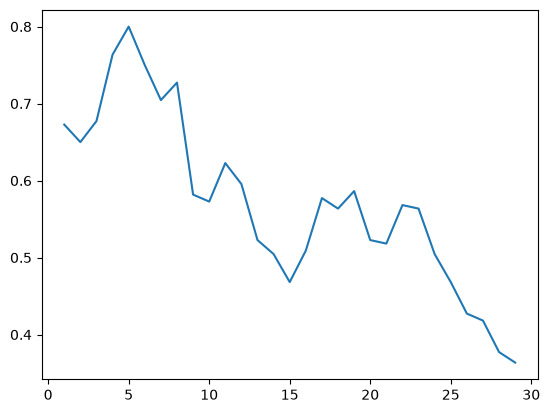

In [129]:
prob = []
Y = []
for i in range(len(bandpass)):
    scores = cross_val_score(clf, epoch_train[i].get_data(), labels[i], cv=cv)
    Y.append(np.mean(scores))
    clf.fit(epoch_train[i].get_data(),labels[i])
    prob.append(clf.predict_proba(epoch_test[i].get_data()))
pred = np.argmax(np.array(prob).mean(0),axis=1)
target = np.array(["move", "rest"])[pred]
dataframe = []
for i in range(len(target)):
    dataframe.append({"ID":i,"TARGET":target[i]})
pd.DataFrame(dataframe).to_csv("result.csv",index=True)
print(target)
plt.plot(range(1,len(Y)+1),Y)